# `spin::Qudit` from C++ to python

The C++ class `spin::Qudit` (file `qudit.hpp`) stores the pure state of one spin $J$, a vector of
$N = 2J+1$ complex amplitudes, and provides state preparations, pulses, time evolution and spin moments.
The file `spin_bindings.cpp` exposes it to Python as the module **`spinlib`**.

**This notebook must be run from the folder that contains** `qudit.hpp` and `spin_bindings.cpp`.

| Section | What it does |
|---|---|
| 1. Setup | installs Eigen and pybind11, runs the C++ tests, builds (or rebuilds) the `spinlib` library |
| 2. Tests from Python | repeats the tests of `test_qudit.cpp` through `spinlib`, comparing with exact results |
| 3. Bloch sphere | interactive pictures and animations of the state on the sphere (Plotly) |
| 4. Playground | non-diagonal evolutions and pulse sequences, with plots |

**Basis convention.** Index $k = 0,\dots,N-1$ is the Dicke state $|J, m\rangle$ with $m = J - k$\
i.e. from $m = +J$ down to $m = -J$, so $|J,J\rangle = (1, 0, \dots, 0)$.

## 1. Setup

### 1.1 Install Eigen and pybind11

Conversion from Eigen vectors/matrices to and from NumPy arrays requires:
* **Eigen**: header-only C++ linear algebra library used by `qudit.hpp`.
* **pybind11**: header-only library that turns C++ classes into Python modules.

To install Eigen:

In [ ]:
!apt-get -qq update > /dev/null && apt-get -qq install -y libeigen3-dev > /dev/null

To install pybind:

In [2]:
%pip install -q pybind11

Note: you may need to restart the kernel to use updated packages.


The cell below ends with three checks: all of them should print `True` (or a path).

In [6]:
import os, sysconfig, pybind11


# Folder that contains qudit.hpp and spin_bindings.cpp (relative to the notebook, or an absolute path)
SRC = os.path.abspath("../src_cpp")

print("Checking library and binding files:")
print("folder   :", os.getcwd())
print("files    :", {f: os.path.exists(os.path.join(SRC,f)) for f in ["qudit.hpp", "spin_bindings.cpp"]})

print("\nChecking Eigen and pybind files:")
print("pybind11 :", pybind11.__version__, "->", pybind11.get_include())
print("Eigen    :", os.path.exists("/usr/include/eigen3/Eigen/Dense"))

print("\nCheck the main header of CPython’s C API:\nThe interface C and C++ code use to talk to the Python interpreter.")
print("Python.h :", os.path.exists(os.path.join(sysconfig.get_paths()["include"], "Python.h")))

Checking library and binding files:
folder   : /home/dario/Projects/QSqueeG/examples
files    : {'qudit.hpp': True, 'spin_bindings.cpp': True}

Checking Eigen and pybind files:
pybind11 : 2.13.6 -> /home/dario/Applications/anaconda3/lib/python3.13/site-packages/pybind11/include
Eigen    : True

Check the main header of CPython’s C API:
The interface C and C++ code use to talk to the Python interpreter.
Python.h : True


### 1.2 Build the Python library `spinlib` from `spin_bindings.cpp`
The result is a file `spinlib.cpython-...so` that Python can `import`. An existing one is deleted first,
so the library is always rebuilt from the current sources. Compilation takes about 10–20 s.

* The **module name** `spinlib` is fixed inside `spin_bindings.cpp` by the line `PYBIND11_MODULE(spinlib, m)`.
* The compiler is called from Python (`subprocess`), so all paths are computed by Python itself.
* **After changing `qudit.hpp` or `spin_bindings.cpp`:** rerun this cell, then *Runtime → Restart session*

In [9]:
import os, sys, sysconfig, subprocess, pybind11

# Build: read the sources from SRC and write the library into SRC
module_file = os.path.join(SRC, "spinlib" + sysconfig.get_config_var("EXT_SUFFIX"))
if os.path.exists(module_file):
    os.remove(module_file)
cmd = ["c++", "-O2", "-shared", "-std=c++17", "-fPIC",
       "-I" + pybind11.get_include(), "-I" + sysconfig.get_paths()["include"],
       "-isystem", "/usr/include/eigen3",
       os.path.join(SRC, "spin_bindings.cpp"), "-o", module_file]
result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout + result.stderr)
print(module_file, "created" if result.returncode == 0 else "-> COMPILATION FAILED")


/home/dario/Projects/QSqueeG/src_cpp/spinlib.cpython-313-x86_64-linux-gnu.so created


## 2. Tests from Python

The same checks as `test_qudit.cpp`, now through the Python module. Every method of the C++ class is
available with the same name; vectors and matrices are NumPy arrays.

Methods that **modify** the state (`prepare...`, `apply...`, `evolve...`) return the qudit itself, so they can be
**chained**: `q.prepareNamed("CSS+Z").applyPulseXPiHalf().avgSy()` prepares, rotates and measures in one line.

In [10]:
import os, sys
import numpy as np

sys.path.insert(0, SRC)                  # make sure Python finds spinlib in this folder
import spinlib

N = 241                                  # Hilbert space dimension: spin J = 20 (e.g. 40 spins 1/2)
J = (N - 1) / 2
np.set_printoptions(precision=4, suppress=True)
print(f"N = {N}, J = {J}")

N = 241, J = 120.0


### 2.1 Named states
A **coherent spin state** (CSS) is the spin fully polarised along one direction: the mean spin has length $J$
along that axis, and the variance in the two perpendicular directions is $J/2$ (the *standard quantum limit*).
The constructor accepts the labels `"CSS+Z"` (default), `"CSS-Z"`, `"CSS+X"`, `"CSS-X"`, `"CSS+Y"`, `"CSS-Y"`.

`printSpin` prints $\langle\psi|\psi\rangle$, the mean values $\langle S_a\rangle$ and the variances
$\mathrm{Var}(S_a) = \langle (S_a - \langle S_a\rangle)^2\rangle$ for $a = x, y, z$.

**Expected:** $\langle S\rangle = \pm J$ along the named axis, $\mathrm{Var} = J/2$ in the other two directions, $0$ along it.

In [11]:
for label in ["CSS+Z", "CSS-X", "CSS+Y"]:
    spinlib.Qudit(N, label).printSpin(label)

CSS+Z :  <psi|psi> = 1
    <Sx> = 0	Var(Sx) = 60
    <Sy> = 0	Var(Sy) = 60
    <Sz> = 120	Var(Sz) = 0
CSS-X :  <psi|psi> = 1
    <Sx> = -120	Var(Sx) = 4.70066e-23
    <Sy> = 0	Var(Sy) = 60
    <Sz> = 0	Var(Sz) = 60
CSS+Y :  <psi|psi> = 1
    <Sx> = 0	Var(Sx) = 60
    <Sy> = 120	Var(Sy) = 4.70066e-23
    <Sz> = 0	Var(Sz) = 60


### 2.2 Coherent state along an arbitrary direction
The method `prepareCSS(theta, phi)` polarises the spin along the unit vector
$\vec n = (\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$ with the angles in radians, and $0\le\theta\le\pi$.

**Expected:** $\langle \vec S\rangle = J\,\vec n$, printed below for comparison.

In [12]:
theta, phi = 0.7, 1.1
q = spinlib.Qudit(N)                                     # one qudit, reused below with the prepare... methods
q.prepareCSS(theta, phi).printSpin("CSS(0.7, 1.1)")
print(f"Expected:  <Sx> = {J*np.sin(theta)*np.cos(phi):.4f}   <Sy> = {J*np.sin(theta)*np.sin(phi):.4f}   <Sz> = {J*np.cos(theta):.4f}")

CSS(0.7, 1.1) :  <psi|psi> = 1
    <Sx> = 35.0658	Var(Sx) = 54.8766
    <Sy> = 68.8958	Var(Sy) = 40.2224
    <Sz> = 91.7811	Var(Sz) = 24.901
Expected:  <Sx> = 35.0658   <Sy> = 68.8958   <Sz> = 91.7811


### 2.3 Dicke states along $z$, $x$ and $y$
A **Dicke state** $|J, m\rangle_a$ has a sharp value $m$ of the spin component along the axis $a$:
zero variance along $a$, and large variance $\big(J(J+1) - m^2\big)/2$ in the two other directions.
The methods `prepareDickeZ(k)`, `prepareDickeX(k)`, `prepareDickeY(k)` take the index $k = J - m$
($k = 0$ is $m = +J$, i.e. the coherent state along $+a$).

The $x$ and $y$ versions are obtained by rotating the $z$ one with exact $\pi/2$ pulses (see 2.4).

In [13]:
k = 3
m = J - k
print(f"Given k = J - m, we expect <S> = {(N - 1)/2} - {k}:")
q.prepareDickeZ(k).printSpin(f"DickeZ k={k}")
q.prepareDickeX(k).printSpin(f"DickeX k={k}")
q.prepareDickeY(k).printSpin(f"DickeY k={k}")
print("Expected transverse variance:", (J*(J + 1) - m**2) / 2)

Given k = J - m, we expect <S> = 120.0 - 3:
DickeZ k=3 :  <psi|psi> = 1
    <Sx> = 0	Var(Sx) = 415.5
    <Sy> = 0	Var(Sy) = 415.5
    <Sz> = 117	Var(Sz) = 0
DickeX k=3 :  <psi|psi> = 1
    <Sx> = 117	Var(Sx) = 9.14949e-26
    <Sy> = 0	Var(Sy) = 415.5
    <Sz> = 0	Var(Sz) = 415.5
DickeY k=3 :  <psi|psi> = 1
    <Sx> = 6.8503e-30	Var(Sx) = 415.5
    <Sy> = 117	Var(Sy) = 9.14949e-26
    <Sz> = 0	Var(Sz) = 415.5
Expected transverse variance: 415.5


### 2.4 Pulses (rotations of the spin)
A pulse of angle $\alpha$ about the axis $a$ is the unitary $e^{-i\alpha S_a}$: it rotates the mean spin
by $\alpha$ about $a$ (right-hand rule).

| Method | Rotation | How it is computed |
|---|---|---|
| `applyPulseZ(phi)` | $e^{-i\varphi S_z}$ | one phase per amplitude (exact for multiples of $\pi/2$) |
| `applyPulseXPi()`, `applyPulseYPi()` | $\pi$ about $x$, $y$ | reversal of the vector, $m\to-m$ (exact) |
| `applyPulseYPiHalf()` | $\pi/2$ about $y$ | stored Wigner matrix $d^J(\pi/2)$ |
| `applyPulseXPiHalf()` | $\pi/2$ about $x$ | $z$ quarter turn · $y$ pulse · $z$ quarter turn back |

Each line applies one pulse and prints the component where the spin should end up;
the expected value is in brackets.

In [14]:
print("Initial state is CSS+Z")
q.prepareNamed("CSS+Z")
print("pi/2 about X on +Z gives -Y:\n-> <Sy> =", round(q.applyPulseXPiHalf().avgSy(), 6), " [-J]")
print("pi/2 about Z on -Y gives +X:\n-> <Sx> =", round(q.applyPulseZ(np.pi/2).avgSx(), 6), " [-J]")
print("pi   about Y on +X gives -X:\n-> <Sx> =", round(q.applyPulseYPi().avgSx(), 6), " [-J]")
print("pi   about Z on -X gives +X:\n-> <Sx> =", round(q.applyPulseZ(np.pi).avgSx(), 6), " [+J]")
print("pi/2 about Y on +X gives -Z:\n-> <Sz> =", round(q.applyPulseYPiHalf().avgSz(), 6), " [+J]")
print("pi   about X on -Z gives +Z:\n-> <Sz> =", round(q.applyPulseXPi().avgSz(), 6), " [+J]")

Initial state is CSS+Z
pi/2 about X on +Z gives -Y:
-> <Sy> = -120.0  [-J]
pi/2 about Z on -Y gives +X:
-> <Sx> = 120.0  [-J]
pi   about Y on +X gives -X:
-> <Sx> = -120.0  [-J]
pi   about Z on -X gives +X:
-> <Sx> = 120.0  [+J]
pi/2 about Y on +X gives -Z:
-> <Sz> = -120.0  [+J]
pi   about X on -Z gives +Z:
-> <Sz> = 120.0  [+J]


### 2.5 Diagonal evolution: one-axis twisting $H = \chi S_z^2$
When $H$ is **diagonal** in the $S_z$ basis, with entries $E_k$, the evolution only multiplies each amplitude
by a phase: $\psi_k \to e^{-iE_k t}\psi_k$. `evolveDiagonal(E, t)` does exactly this: exact for any $t$, cost $O(N)$.

One-axis twisting ($E_k = \chi m^2$) shears the state: starting from CSS+X, the mean spin shrinks and the
variance $\mathrm{Var}(S_y)$ grows. **Exact result:** $\langle S_x\rangle(t) = J\cos(\chi t)^{2J-1}$.
Here the evolution is applied in steps of $dt$, each one starting from the previous state.

In [15]:
chi, dt = 0.25, 0.1
E_oat = chi * np.array([q.spinM(k)**2 for k in range(N)])     # diagonal of H = chi Sz^2, E_k = chi m^2

q.prepareNamed("CSS+X")
for step in range(1, 11):
    q.evolveDiagonal(E_oat, dt)                              # psi(t + dt) from psi(t)
    t = step * dt
    print(f"t = {t:.2f} :  <Sx> = {q.avgSx():.4f}   exact = {J*np.cos(chi*t)**(2*J - 1):.4f}   Var(Sy) = {q.varSy():.4f}")

t = 0.10 :  <Sx> = 111.3631   exact = 111.3631   Var(Sy) = 1905.6981
t = 0.20 :  <Sx> = 88.9983   exact = 88.9983   Var(Sy) = 5053.0670
t = 0.30 :  <Sx> = 61.2322   exact = 61.2322   Var(Sy) = 6742.1248
t = 0.40 :  <Sx> = 36.2520   exact = 36.2520   Var(Sy) = 7170.5233
t = 0.50 :  <Sx> = 18.4566   exact = 18.4566   Var(Sy) = 7226.0985
t = 0.60 :  <Sx> = 8.0736   exact = 8.0736   Var(Sy) = 7229.8643
t = 0.70 :  <Sx> = 3.0312   exact = 3.0312   Var(Sy) = 7229.9975
t = 0.80 :  <Sx> = 0.9756   exact = 0.9756   Var(Sy) = 7230.0000
t = 0.90 :  <Sx> = 0.2688   exact = 0.2688   Var(Sy) = 7230.0000
t = 1.00 :  <Sx> = 0.0633   exact = 0.0633   Var(Sy) = 7230.0000


### 2.6 Non-diagonal evolution: Rabi rotation $H = \Omega S_x$
For a general Hamiltonian, `evolve(E, P, t)` uses its diagonalisation $H = P\,\mathrm{diag}(E)\,P^\dagger$:

$$\psi(t) = e^{-iHt}\psi = P\,\mathrm{diag}\big(e^{-iE_j t}\big)\,P^\dagger\psi,$$

i.e. rotate into the eigenbasis of $H$ ($P^\dagger$), apply the phases (`evolveDiagonal`), rotate back ($P$).

The Hamiltonian is built here as an $N\times N$ NumPy matrix and diagonalised **once** with `np.linalg.eigh`; `evolve` then gives the state at **any** time $t$, at cost $O(N^2)$.

The helper `spin_matrices(N)` builds $S_x, S_y, S_z$ in the same basis as the C++ class, from the ladder coefficients $\langle J,m|S_+|J,m-1\rangle = \sqrt{J(J+1) - m(m-1)}$.

$H = \Omega S_x$ rotates the spin about $x$. Starting from CSS+Z, **exact result:**
$\langle S_z\rangle = J\cos\Omega t$ and $\ \mathrm{Var}(S_z) = \tfrac{J}{2}\sin^2\Omega t$.\
Each time starts again from CSS+Z (`prepareNamed`), so the numbers do not depend on previous steps.

In [16]:
def spin_matrices(N):
    # Sx, Sy, Sz as N x N complex NumPy matrices, in the basis |J, m>, m = J - k (same convention as qudit.hpp).
    J = (N - 1) / 2
    m = J - np.arange(N)                                     # m = J, J-1, ..., -J
    l = np.sqrt(J*(J + 1) - m[:-1]*(m[:-1] - 1))             # <J,m|S_+|J,m-1>
    Sp = np.diag(l, 1).astype(complex)                       # S_+ : one step above the diagonal
    Sx = (Sp + Sp.conj().T) / 2                              # S_x = (S_+ + S_-)/2
    Sy = (Sp - Sp.conj().T) / 2j                             # S_y = (S_+ - S_-)/(2i)
    Sz = np.diag(m).astype(complex)
    return Sx, Sy, Sz

Sx, Sy, Sz = spin_matrices(N)
Omega = 1.0
E, P = np.linalg.eigh(Omega * Sx)                           # diagonalise ONCE: eigenvalues E, eigenvectors = columns of P

print("     t      <Sz>     exact    Var(Sz)    exact")
for t in np.linspace(0, np.pi, 9):
    q.prepareNamed("CSS+Z").evolve(E, P, t)
    print(f"{t:6.4f} {q.avgSz():9.4f} {J*np.cos(Omega*t):9.4f} {q.varSz():9.4f} {J/2*np.sin(Omega*t)**2:9.4f}")

     t      <Sz>     exact    Var(Sz)    exact
0.0000  120.0000  120.0000    0.0000    0.0000
0.3927  110.8655  110.8655    8.7868    8.7868
0.7854   84.8528   84.8528   30.0000   30.0000
1.1781   45.9220   45.9220   51.2132   51.2132
1.5708   -0.0000    0.0000   60.0000   60.0000
1.9635  -45.9220  -45.9220   51.2132   51.2132
2.3562  -84.8528  -84.8528   30.0000   30.0000
2.7489 -110.8655 -110.8655    8.7868    8.7868
3.1416 -120.0000 -120.0000    0.0000    0.0000


### 2.7 Save / load, and errors
`save(file)` writes the amplitudes to a text file with 17 significant digits; `load(file)` reads them back exactly
(and refuses a file written for a different $N$).

C++ exceptions arrive in Python as ordinary exceptions:
`std::invalid_argument` → `ValueError`, `std::out_of_range` → `IndexError`, `std::runtime_error` → `RuntimeError`.

In [17]:
q.prepareCSS(theta, phi).save("q_test.txt")
loaded = spinlib.Qudit(N)
loaded.load("q_test.txt")
print("save/load: max |difference| =", np.abs(loaded.state() - q.state()).max())

for action in (lambda: spinlib.Qudit(N + 3).load("q_test.txt"),   # file written for another N
               lambda: spinlib.Qudit(N, "CSS+W"),                  # unknown label
               lambda: q.prepareDickeZ(N)):                        # index outside 0..N-1
    try:
        action()
    except Exception as e:
        print("expected error:", type(e).__name__, "-", e)
os.remove("q_test.txt")

save/load: max |difference| = 0.0
expected error: RuntimeError - Qudit::load: N in "q_test.txt" differs from the qudit's N
expected error: ValueError - Qudit: unknown initial state "CSS+W".
expected error: IndexError - Qudit: basis index 241 out of range


## 3. Bloch sphere

A spin $J$ can be drawn on the sphere through its **Husimi function**
$$Q(\theta,\varphi) = |\langle \theta,\varphi|\psi\rangle|^2,$$
the overlap of the state with the coherent spin state pointing at $(\theta, \varphi)$. \
It is $1$ exactly where the state *is* the coherent state pointing there:

| Picture | State |
|---|---|
| a round spot | coherent spin state |
| an ellipse | squeezed state |
| a ring | Dicke state |
| several spots | superposition of coherent states (cat state) |

The work is split between the two languages:
* **C++** computes $Q$ on a $\theta\times\varphi$ grid: `q.husimiQ(nTheta, nPhi)` returns a NumPy array with
  $\theta_i = \pi i/(n_\theta-1)$ from the north pole ($+z$) to the south pole ($-z$), and
  $\varphi_j = 2\pi j/(n_\varphi-1)$, the last column repeating $\varphi = 0$ to close the sphere.
* **Python** draws it with **Plotly**, which gives interactive figures: drag to rotate, scroll to zoom,
  hover to read $Q$ and the mean spin.

### 3.1 Plotting functions
First the helpers: the grid of points on the sphere (the same as in `husimiQ`), the mean spin, and the pieces
of the figure (coloured sphere, arrow, axes, layout).

In [18]:
import numpy as np
try:
    import plotly.graph_objects as go                  # preinstalled on Colab
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plotly"], check=True)
    import plotly.graph_objects as go


def sphere_grid(n_theta, n_phi):
    # Cartesian coordinates of the same (theta, phi) grid used by Qudit.husimiQ:
    #     theta_i = pi i / (n_theta - 1),   phi_j = 2 pi j / (n_phi - 1).
    theta = np.linspace(0.0, np.pi, n_theta)
    phi = np.linspace(0.0, 2.0 * np.pi, n_phi)
    TH, PH = np.meshgrid(theta, phi, indexing="ij")    # shape (n_theta, n_phi), like the matrix Q
    return np.sin(TH) * np.cos(PH), np.sin(TH) * np.sin(PH), np.cos(TH)


def mean_spin(q):
    # Mean spin <S>/J: a vector of length 1 for a coherent state, shorter for other states.
    J = q.spinJ()
    return np.array([q.avgSx(), q.avgSy(), q.avgSz()]) / J if J > 0 else np.zeros(3)


def bloch_traces(q, n_theta, n_phi, cmax, show_mean):
    # Plotly traces for the current state of q: the sphere coloured with Q and the mean-spin arrow.
    x, y, z = sphere_grid(n_theta, n_phi)
    # Q is computed in C++. dtype=float converts it to ordinary 64-bit floats, also when the library is
    # built in long double (NumPy float128), which Plotly cannot handle.
    Q = np.asarray(q.husimiQ(n_theta, n_phi), dtype=float)
    traces = [go.Surface(x=x, y=y, z=z, surfacecolor=Q, cmin=0.0, cmax=cmax if cmax is not None else Q.max(),
                         colorscale="Viridis", colorbar=dict(title="Q", len=0.6),
                         hovertemplate="Q = %{surfacecolor:.3f}<extra></extra>")]
    if show_mean:
        # Arrow along the DIRECTION of <S>, from the sphere surface outwards, so it is always visible
        # (also when |<S>|/J < 1 and the vector itself would end inside the sphere); hover on it for <S>/J.
        # No arrow when <S> = 0 (Dicke states along z, cat states).
        # Note: Plotly reads "<...>" in labels as HTML tags, hence the Unicode brackets ⟨S⟩.
        s = mean_spin(q)
        length = np.linalg.norm(s)
        u = s / length if length > 1e-9 else np.zeros(3)
        start, tip = 1.0 * u, 1.3 * u
        hover = f"⟨S⟩/J = ({s[0]:.3f}, {s[1]:.3f}, {s[2]:.3f}),  |⟨S⟩|/J = {length:.3f}<extra></extra>"
        visible = bool(length > 1e-9)
        traces.append(go.Scatter3d(x=[start[0], tip[0]], y=[start[1], tip[1]], z=[start[2], tip[2]],
                                   mode="lines", line=dict(color="red", width=6), hovertemplate=hover, visible=visible))
        traces.append(go.Cone(x=[tip[0]], y=[tip[1]], z=[tip[2]], u=[u[0]], v=[u[1]], w=[u[2]],
                              sizemode="absolute", sizeref=0.12, anchor="tip", showscale=False,
                              colorscale=[[0, "red"], [1, "red"]], hoverinfo="skip", visible=visible))
    return traces


def bloch_axes():
    # The x, y, z axes as thin gray lines with labels, slightly longer than the sphere.
    L = 1.35
    traces = []
    for (dx, dy, dz), label in [((1, 0, 0), "x"), ((0, 1, 0), "y"), ((0, 0, 1), "z")]:
        traces.append(go.Scatter3d(x=[-L*dx, L*dx], y=[-L*dy, L*dy], z=[-L*dz, L*dz], mode="lines+text",
                                   text=["", label], textfont=dict(size=16), line=dict(color="gray", width=2),
                                   hoverinfo="skip", showlegend=False))
    return traces


def bloch_layout(title):
    # Hidden cartesian axes, equal aspect ratio, and a camera looking from between x and y.
    hidden = dict(visible=False, range=[-1.4, 1.4])
    return dict(title=title, showlegend=False, height=550, margin=dict(l=0, r=0, t=40, b=0),
                scene=dict(xaxis=hidden, yaxis=hidden, zaxis=hidden, aspectmode="cube",
                           camera=dict(eye=dict(x=1.15, y=0.85, z=0.65))))

**One state:** `bloch_figure(q)` draws the current state of the qudit `q`. The red arrow shows the direction of
the mean spin $\langle\vec S\rangle$. The colour scale goes from $0$ to the maximum of $Q$ for this state
(or to `cmax`, if given).

In [19]:
def bloch_figure(q, title=None, n_theta=61, n_phi=121, cmax=None, show_mean=True):
    # Interactive Bloch sphere of the current state of q (61 x 121 grid points by default).
    if title is None:
        s = mean_spin(q)
        title = f"N = {q.dim()},  ⟨S⟩/J = ({s[0]:.2f}, {s[1]:.2f}, {s[2]:.2f})"
    return go.Figure(data=bloch_traces(q, n_theta, n_phi, cmax, show_mean) + bloch_axes(), layout=bloch_layout(title))

**A time evolution:** `bloch_animation(state_at, times)` draws one frame per time, with a slider and a play button.
`state_at` is any function $t \mapsto$ qudit at time $t$, for example
`lambda t: q.prepareNamed("CSS+X").evolve(E, P, t)`, so it works with `evolveDiagonal`, `evolve` or pulse sequences.
All frames share the same colour scale (the maximum of $Q$ over all of them), so colours can be compared in time.

In [20]:
def bloch_animation(state_at, times, title="", n_theta=41, n_phi=81, show_mean=True):
    # Each frame is computed immediately after state_at(t), since state_at usually returns the same qudit.
    frames_traces = [bloch_traces(state_at(t), n_theta, n_phi, None, show_mean) for t in times]
    cmax = max(float(np.max(tr[0].surfacecolor)) for tr in frames_traces)
    for tr in frames_traces:
        tr[0].cmax = cmax                                   # common colour scale

    labels = [f"{t:.3g}" for t in times]
    n_changing = len(frames_traces[0])                      # sphere and arrow change, the axes do not
    frames = [go.Frame(data=tr, name=lab, traces=list(range(n_changing))) for tr, lab in zip(frames_traces, labels)]
    fig = go.Figure(data=frames_traces[0] + bloch_axes(), frames=frames, layout=bloch_layout(title))

    play = dict(label="play", method="animate",
                args=[None, dict(frame=dict(duration=150, redraw=True), fromcurrent=True, transition=dict(duration=0))])
    pause = dict(label="pause", method="animate",
                 args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])
    fig.update_layout(
        updatemenus=[dict(type="buttons", buttons=[play, pause], x=0.05, y=0.05, xanchor="left", yanchor="bottom")],
        sliders=[dict(active=0, currentvalue=dict(prefix="t = "), x=0.2, len=0.75, y=0.02,
                      steps=[dict(label=lab, method="animate",
                                  args=[[lab], dict(frame=dict(duration=0, redraw=True), mode="immediate")])
                             for lab in labels])])
    return fig

### 3.2 A coherent state
The coherent state of 2.2: a round spot centred on the direction $(\theta, \varphi) = (0.7, 1.1)$,
with the arrow pointing at its centre. Try rotating the sphere with the mouse.

In [21]:
N = 41                                    # a smaller spin than in section 2: spots are larger and easier to see
J = (N - 1) / 2
q = spinlib.Qudit(N)
bloch_figure(q.prepareCSS(0.7, 1.1), title="coherent state along (theta, phi) = (0.7, 1.1)").show()

### 3.3 A gallery of states
* **Dicke state along $x$** with $k = 10$ ($m_x = J - 10$): a ring around the $x$ axis, at the height where $S_x = m$.
* **One-axis twisted state** ($H = \chi S_z^2$, short time): the spot of CSS+X is stretched into an ellipse,
  squeezed in one direction and anti-squeezed in the other.
* **Cat state**: one-axis twisting until $\chi t = \pi/2$ turns CSS+X into a superposition of two opposite coherent
  states (for this $N$, along $\pm x$). $Q$ has two spots, so rotate the sphere to see the second one;
  $\langle\vec S\rangle = 0$, so there is no arrow.

In [22]:
chi = 0.5
E_oat = chi * np.array([q.spinM(k)**2 for k in range(N)])      # H = chi Sz^2 is diagonal: E_k = chi m^2

bloch_figure(q.prepareDickeX(10), title="Dicke state along x, k = 10").show()
bloch_figure(q.prepareNamed("CSS+X").evolveDiagonal(E_oat, 0.1), title="one-axis twisting, chi t = 0.05").show()
bloch_figure(q.prepareNamed("CSS+X").evolveDiagonal(E_oat, np.pi / (2*chi)), title="cat state, chi t = pi/2").show()

### 3.4 Animation: one-axis twisting
The spot of CSS+X shears into an ellipse, wraps around the equator and, at $\chi t = \pi/2$, splits into the
cat state of 3.3. Move the slider or press *play*.

In [36]:
times = np.linspace(0, np.pi / (2*chi), 61)
bloch_animation(lambda t: q.prepareNamed("CSS+X").evolveDiagonal(E_oat, t), times,
                title="one-axis twisting  H = chi Sz^2").show()

### 3.5 Animation: twisting and turning $H = \chi S_z^2 + \Omega S_x$
A non-diagonal evolution (studied quantitatively in 4.2): the state is squeezed quickly, and then spreads over
the sphere. $H$ is built with `spin_matrices` from 2.6 and diagonalised once. Change $\chi$ and $\Omega$ and rerun.

In [37]:
chi_tt, Omega_tt = 0.05, 0.5
Sx, Sy, Sz = spin_matrices(N)
E_tt, P_tt = np.linalg.eigh(chi_tt * Sz @ Sz + Omega_tt * Sx)      # diagonalise once

times = np.linspace(0, 4, 41)
bloch_animation(lambda t: q.prepareNamed("CSS+X").evolve(E_tt, P_tt, t), times,
                title="twisting and turning  H = chi Sz^2 + Omega Sx").show()

## 4. Playground

Change the parameters at the top of each cell and rerun it. The pattern is always the same:

1. build $H$ from `spin_matrices(N)` and diagonalise it once with `np.linalg.eigh`,
2. for each time, prepare the initial state and call `evolve(E, P, t)`,
3. read the moments (`avgSx`, `varSz`, ...) or the full state (`q.state()`, a NumPy array).

### 4.1 Rabi rotation: numerics vs exact formulas
The same evolution as in 2.6, over two full periods: the curves of `spinlib` and of the exact formulas
should lie on top of each other.

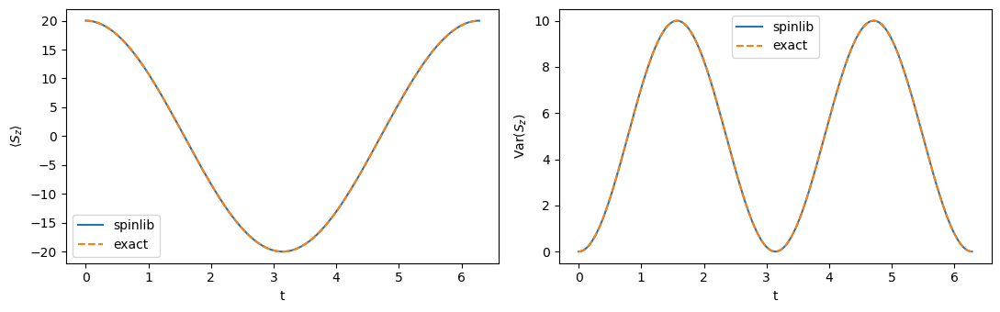

In [30]:
import matplotlib.pyplot as plt

N, Omega = 41, 1.0                         # parameters: dimension and Rabi frequency
J = (N - 1) / 2
Sx, Sy, Sz = spin_matrices(N)
E, P = np.linalg.eigh(Omega * Sx)          # H = Omega Sx, diagonalised once

times = np.linspace(0, 2*np.pi / Omega, 200)
q = spinlib.Qudit(N)
mean, var = [], []
for t in times:
    q.prepareNamed("CSS+Z").evolve(E, P, t)
    mean.append(q.avgSz())
    var.append(q.varSz())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(times, mean, label="spinlib");  ax[0].plot(times, J*np.cos(Omega*times), "--", label="exact")
ax[1].plot(times, var,  label="spinlib");  ax[1].plot(times, J/2*np.sin(Omega*times)**2, "--", label="exact")
ax[0].set(xlabel="t", ylabel=r"$\langle S_z\rangle$"); ax[1].set(xlabel="t", ylabel=r"Var$(S_z)$")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

### 4.2 Twisting and turning: $H = \chi S_z^2 + \Omega S_x$
A genuinely non-diagonal Hamiltonian with no simple closed form: the twisting term $\chi S_z^2$ shears the
fluctuations, the transverse field $\Omega S_x$ rotates them.

Starting from CSS+X, the mean spin stays along $x$ (both $H$ and the initial state are symmetric under a
$\pi$ rotation about $x$), while the fluctuations in the $y$–$z$ plane are reshaped. To quantify this:

* $\mathrm{Var}_{\min}$: the **smallest variance in the $y$–$z$ plane**, i.e. of $S_y\cos\alpha + S_z\sin\alpha$
  minimised over $\alpha$. It is the smallest eigenvalue of the $2\times2$ covariance matrix of $(S_y, S_z)$,
  computed here in NumPy from `q.state()` (the covariance is not a method of the class).
* the **Wineland squeezing parameter** $\xi^2 = 2J\,\mathrm{Var}_{\min}/\langle S_x\rangle^2$, which is $1$ for a
  coherent state; $\xi^2 < 1$ means **spin squeezing** (improved precision in Ramsey interferometry).

Try changing $\chi$ and $\Omega$: for $\Omega = 0$ you get pure one-axis twisting.

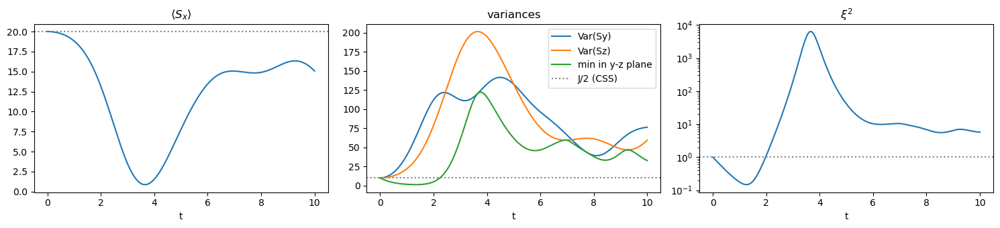

best squeezing: xi^2 = 0.1477 at t = 1.271


In [31]:
N, chi, Omega, t_max = 41, 0.05, 0.5, 10.0          # parameters
J = (N - 1) / 2
Sx, Sy, Sz = spin_matrices(N)
E, P = np.linalg.eigh(chi * Sz @ Sz + Omega * Sx)   # H = chi Sz^2 + Omega Sx, diagonalised once

def min_transverse_variance(psi):
    # Smallest variance of S_y cos(a) + S_z sin(a) over the angle a, i.e. the smallest eigenvalue of
    #     C = [[Var Sy, Cov], [Cov, Var Sz]],   Cov = Re<(Sy Sz + Sz Sy)/2> - <Sy><Sz>.
    ev = lambda A: np.vdot(psi, A @ psi).real        # <psi|A|psi> for a Hermitian A
    y, z = ev(Sy), ev(Sz)
    cov = 0.5 * ev(Sy @ Sz + Sz @ Sy) - y * z
    C = np.array([[ev(Sy @ Sy) - y*y, cov], [cov, ev(Sz @ Sz) - z*z]])
    return np.linalg.eigvalsh(C)[0]                  # eigenvalues in increasing order: take the first

times = np.linspace(0, t_max, 300)
q = spinlib.Qudit(N)
data = {key: [] for key in ["Sx", "VarSy", "VarSz", "Vmin", "xi2"]}
for t in times:
    q.prepareNamed("CSS+X").evolve(E, P, t)
    sx, vmin = q.avgSx(), min_transverse_variance(q.state())
    data["Sx"].append(sx)
    data["VarSy"].append(q.varSy())
    data["VarSz"].append(q.varSz())
    data["Vmin"].append(vmin)
    data["xi2"].append(2 * J * vmin / sx**2)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(times, data["Sx"]); ax[0].axhline(J, color="gray", ls=":")
ax[1].plot(times, data["VarSy"], label="Var(Sy)"); ax[1].plot(times, data["VarSz"], label="Var(Sz)")
ax[1].plot(times, data["Vmin"], label="min in y-z plane"); ax[1].axhline(J/2, color="gray", ls=":", label="J/2 (CSS)")
ax[2].semilogy(times, data["xi2"]); ax[2].axhline(1, color="gray", ls=":")
ax[0].set(xlabel="t", title=r"$\langle S_x\rangle$"); ax[1].set(xlabel="t", title="variances"); ax[2].set(xlabel="t", title=r"$\xi^2$")
ax[1].legend()
plt.tight_layout(); plt.show()
best = int(np.argmin(data["xi2"]))
print(f"best squeezing: xi^2 = {data['xi2'][best]:.4f} at t = {times[best]:.3f}")

### 4.3 Ramsey interferometry
The basic sequence of atomic clocks and interferometers:

1. a $\pi/2$ pulse about $y$ turns the spin from $+z$ to the equator ($+x$),
2. during a free evolution time $T$ with detuning $\delta$ the spin precesses about $z$ by the angle $\delta T$
   (`applyPulseZ(delta*T)`),
3. a second $\pi/2$ pulse about $y$ maps that angle back onto $S_z$.

The final population imbalance is $\langle S_z\rangle = -J\cos(\delta T)$: the **Ramsey fringes**.
Only pulses are used here, no matrices.

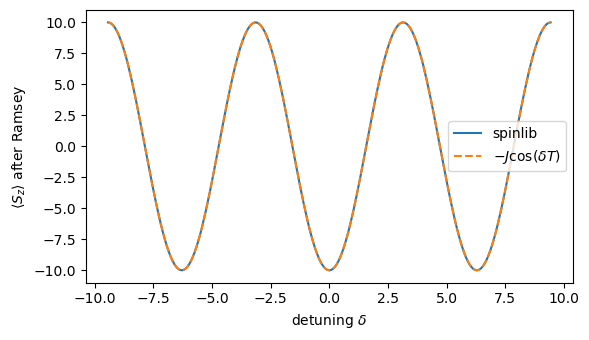

In [32]:
N, T = 21, 1.0                                       # parameters: dimension and free evolution time
J = (N - 1) / 2
deltas = np.linspace(-3*np.pi, 3*np.pi, 241)
q = spinlib.Qudit(N)
sz = [q.prepareNamed("CSS+Z").applyPulseYPiHalf().applyPulseZ(d*T).applyPulseYPiHalf().avgSz() for d in deltas]

plt.figure(figsize=(6, 3.5))
plt.plot(deltas, sz, label="spinlib"); plt.plot(deltas, -J*np.cos(deltas*T), "--", label=r"$-J\cos(\delta T)$")
plt.xlabel(r"detuning $\delta$"); plt.ylabel(r"$\langle S_z\rangle$ after Ramsey"); plt.legend(); plt.tight_layout(); plt.show()